# CS07 - Real case A: how much solar and storage for the Niamey area? (hourly year 2023)

**Problem type:** planning under variability - capacity expansion and hourly dispatch with
network constraints, then AC security checks at the critical hours.

**Data:**
* **Real weather, hourly, 2023:** NASA POWER satellite data for Niamey (13.51 N, 2.11 E):
  irradiance (CERES SYN1deg) and temperature (MERRA-2). PV output computed with pvlib, the
  same model chain as Renewables.ninja. If a Renewables.ninja CSV is placed in
  `data/raw/renewables_ninja/niamey_pv_2023.csv`, it is used automatically instead.
* **Demand:** temperature-driven model (real temperatures), peak 105 MW.
* **Grid and costs:** the five-bus network of CS03 (fictitious) with the 15 MVAr bank;
  costs in `src/pscs/assumptions.py` (ranges from IRENA, NREL ATB, IPCC).

## 1. The decision question
The Niamey area relies on a thermal plant (HFO/diesel, about 180 $/MWh of fuel) and on
imports through an interconnector (cheaper, but they can be interrupted: in 2023 the
suspension of imports from Nigeria showed how exposed the city is). **How much solar and
battery capacity minimises the yearly cost of supply, with and without imports, and what
does it change for fuel, CO2 and the grid?**

## 2. Exercise
1. Optimise six scenarios over the 8760 hours of 2023 (table below).
2. Compare yearly cost, average cost per MWh, fuel use and CO2.
3. Explain the optimal PV and battery sizes. What limits the PV size?
4. Show how the system operates during a hot-season week.
5. Check the AC load flow at the two critical hours (evening peak, solar peak).

| Scenario | Imports | New PV | New battery |
|---|---|---|---|
| A | available (80 MW) | none | none |
| B | interrupted | none | none |
| C | interrupted | 100 MW (the plan of the exercise) | none |
| D0 | interrupted | optimised | none |
| D | interrupted | optimised | optimised |
| E | available | optimised | optimised |

## 3. Method
PyPSA's **linear optimal power flow** (`n.optimize()`) minimises
$$\sum_{\text{assets}} c^{cap}_a\,\bar P_a \;+\; \sum_t \sum_g c^{var}_g\,p_{g,t}$$
over the 8760 hours, subject to: hourly power balance at every bus, linearised line flows
within 90 % of the 100 MVA rating, PV output $\le$ capacity $\times$ hourly capacity factor,
battery state-of-charge dynamics (4 h, 90 % round trip). $c^{cap}$ is the **annualised**
investment (capital recovery factor at 8 %, plus fixed O&M).

**Operating assumption:** when imports are interrupted the grid runs as an **island**; the
thermal plant must then keep at least 20 MW online (synchronous inertia and frequency
control). With imports, the interconnection provides this service.

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs import assumptions as A
from pscs.solar import pv_profile
from pscs.kpi import run_pf
from pscs.plotting import ENTITY, SERIES, CRITICAL, INK2, MUTED, save, limit_line

DATA, FIG, TAB = pscs.setup()
PATH = DATA / "networks" / "niamey_grid_2023"
n0 = pypsa.Network(PATH)
cf = n0.generators_t.p_max_pu["pv"]
demand = n0.loads_t.p_set.sum(axis=1)
print(f"PV data source: {pv_profile('niamey').name}")
print(f"PV capacity factor 2023: {cf.mean():.1%} ({cf.sum():.0f} kWh/kWp)")
print(f"Demand: {demand.sum() / 1e3:.0f} GWh, peak {demand.max():.0f} MW on {demand.idxmax()}")
print(f"Annualised costs: PV {A.pv_capital_cost() / 1e3:.1f} k$/MW/yr, "
      f"battery (4 h) {A.battery_capital_cost() / 1e3:.1f} k$/MW/yr")
print(f"PV levelised cost if fully used: {A.pv_capital_cost() / cf.sum():.0f} $/MWh "
      f"vs thermal fuel {A.THERMAL_MC:.0f} $/MWh and imports {A.IMPORT_MC:.0f} $/MWh")

PV data source: NASA POWER + pvlib
PV capacity factor 2023: 19.5% (1710 kWh/kWp)
Demand: 726 GWh, peak 105 MW on 2023-05-04 19:00:00
Annualised costs: PV 86.9 k$/MW/yr, battery (4 h) 157.4 k$/MW/yr
PV levelised cost if fully used: 51 $/MWh vs thermal fuel 180 $/MWh and imports 70 $/MWh


## 4. Monthly solar resource and demand (real 2023 data)

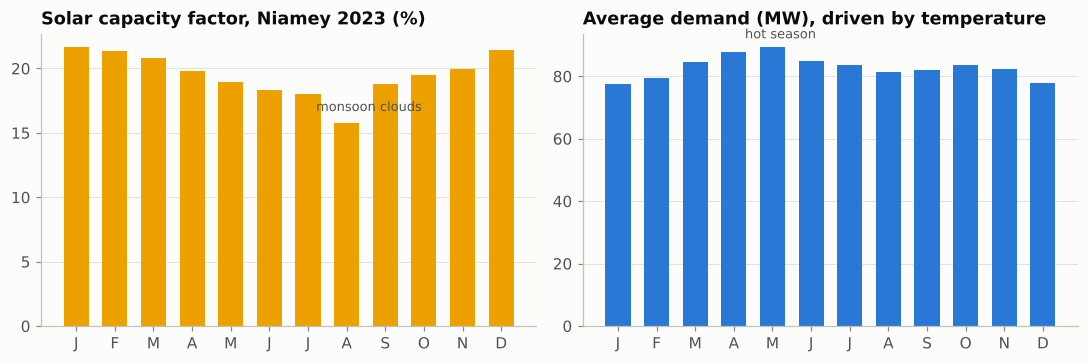

In [2]:
monthly = pd.DataFrame({"PV capacity factor (%)": 100 * cf.groupby(cf.index.month).mean(),
                        "average demand (MW)": demand.groupby(demand.index.month).mean()})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
months = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
axes[0].bar(range(12), monthly["PV capacity factor (%)"], color=ENTITY["solar"], width=0.65)
axes[0].set_title("Solar capacity factor, Niamey 2023 (%)")
axes[1].bar(range(12), monthly["average demand (MW)"], color=ENTITY["demand"], width=0.65)
axes[1].set_title("Average demand (MW), driven by temperature")
for ax in axes:
    ax.set_xticks(range(12)); ax.set_xticklabels(months); ax.grid(axis="x", visible=False)
axes[0].annotate("monsoon clouds", (7, monthly.iloc[7, 0]), xytext=(-20, 8), textcoords="offset points",
                 fontsize=8.5, color=INK2)
axes[1].annotate("hot season", (4, monthly.iloc[4, 1]), xytext=(-18, 6), textcoords="offset points",
                 fontsize=8.5, color=INK2)
fig.tight_layout()
save(fig, FIG / "cs07_monthly_resource_demand.png")
fig

## 5. Optimise the six scenarios

In [3]:
SCEN = {"A": dict(imports=True, pv=0, bat=0), "B": dict(imports=False, pv=0, bat=0),
        "C": dict(imports=False, pv=100, bat=0), "D0": dict(imports=False, pv=None, bat=0),
        "D": dict(imports=False, pv=None, bat=None),
        "E": dict(imports=True, pv=None, bat=None)}
NAMES = {"A": "A imports, no PV", "B": "B no imports, no PV", "C": "C no imports, 100 MW PV",
         "D0": "D0 no imports, optimal PV, no battery",
         "D": "D no imports, optimal PV+battery", "E": "E imports, optimal PV+battery"}


MUST_RUN = 20.0      # MW of thermal always online when the grid runs islanded (assumption)


def build(imports, pv, bat):
    n = pypsa.Network(PATH)
    if not imports:
        n.generators.loc["import", "p_nom"] = 0.0
        # islanded operation: synchronous machines must stay online for inertia and
        # frequency control -> the thermal plant never goes below MUST_RUN
        n.generators.loc["thermal", "p_min_pu"] = MUST_RUN / n.generators.loc["thermal", "p_nom"]
    if pv is not None:
        n.generators.loc["pv", ["p_nom_extendable", "p_nom"]] = [False, pv]
    if bat is not None:
        n.storage_units.loc["battery", ["p_nom_extendable", "p_nom"]] = [False, bat]
    return n


def results(n):
    g, s = n.generators, n.storage_units
    gp = n.generators_t.p
    pv_mw, bat_mw = g.p_nom_opt["pv"], s.p_nom_opt["battery"]
    pv_avail = (pv_mw * n.generators_t.p_max_pu["pv"]).sum()
    capex = pv_mw * g.capital_cost["pv"] + bat_mw * s.capital_cost["battery"]
    opex = (gp["thermal"] * A.THERMAL_MC + gp["import"] * A.IMPORT_MC).sum()
    flows = n.lines_t.p0.abs().div(n.lines.s_nom)
    return {"PV (MW)": pv_mw, "battery (MW)": bat_mw, "battery (MWh)": bat_mw * A.BAT_HOURS,
            "PV energy used (GWh)": gp["pv"].sum() / 1e3,
            "PV curtailed (%)": 100 * (1 - gp["pv"].sum() / pv_avail) if pv_avail > 0 else 0.0,
            "solar share (%)": 100 * gp["pv"].sum() / demand.sum(),
            "thermal (GWh)": gp["thermal"].sum() / 1e3, "imports (GWh)": gp["import"].sum() / 1e3,
            "CO2 (kt)": gp["thermal"].sum() * A.THERMAL_CO2 / 1e3,
            "capex (M$/yr)": capex / 1e6, "fuel+imports (M$/yr)": opex / 1e6,
            "total cost (M$/yr)": (capex + opex) / 1e6,
            "average cost ($/MWh)": (capex + opex) / demand.sum(),
            "max line loading (%)": 100 * flows.max().max(),
            "hours at line limit": int((flows >= 0.9 - 1e-4).any(axis=1).sum()),
            "thermal peak (MW)": gp["thermal"].max()}

nets, table = {}, {}
for k, sc in SCEN.items():
    t0 = time.time()
    n = build(**sc)
    status, cond = n.optimize(solver_name="highs", solver_options={"output_flag": False})
    assert status == "ok", cond
    nets[k], table[NAMES[k]] = n, results(n)
    print(f"scenario {k}: solved in {time.time() - t0:.0f} s")
res = pd.DataFrame(table).T
res.to_csv(TAB / "cs07_scenarios.csv")
res.round(2)

Writing constraints.:   0%|          | 0/13 [00:00<?, ?it/s]

Writing constraints.:  85%|████████▍ | 11/13 [00:00<00:00, 86.07it/s]

Writing constraints.: 100%|██████████| 13/13 [00:00<00:00, 84.72it/s]

Writing continuous variables.:   0%|          | 0/5 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 5/5 [00:00<00:00, 205.84it/s]

scenario A: solved in 3 s


... (27 outputs left out)

Writing continuous variables.:   0%|          | 0/7 [00:00<?, ?it/s]

Writing continuous variables.: 100%|██████████| 7/7 [00:00<00:00, 197.19it/s]

scenario E: solved in 13 s


,PV (MW),battery (MW),battery (MWh),PV energy used (GWh),PV curtailed (%),solar share (%),thermal (GWh),imports (GWh),CO2 (kt),capex (M$/yr),fuel+imports (M$/yr),total cost (M$/yr),average cost ($/MWh),max line loading (%),hours at line limit,thermal peak (MW)
"A imports, no PV",0.00,0.00,0.00,0.00,0.00,0.00,50.36,675.71,35.25,0.00,56.36,56.36,77.63,55.42,0.0,25.00
"B no imports, no PV",0.00,0.00,0.00,0.00,0.00,0.00,726.07,0.00,508.25,0.00,130.69,130.69,180.00,55.42,0.0,105.00
"C no imports, 100 MW PV",100.00,0.00,0.00,167.13,2.28,23.02,558.94,0.00,391.26,8.69,100.61,109.30,150.54,62.54,0.0,105.00
"D0 no imports, optimal PV, no battery",153.86,0.00,0.00,210.50,20.01,28.99,515.57,0.00,360.90,13.38,92.80,106.18,146.24,63.78,0.0,105.00
"D no imports, optimal PV+battery",333.48,195.72,782.89,519.47,8.92,71.55,232.91,0.00,163.03,59.79,41.92,101.71,140.09,67.29,0.0,104.28
"E imports, optimal PV+battery",143.94,8.35,33.39,239.75,2.61,33.02,9.66,477.89,6.76,13.83,35.19,49.02,67.51,67.11,0.0,24.42


## 6. Cost and emissions (question 2)

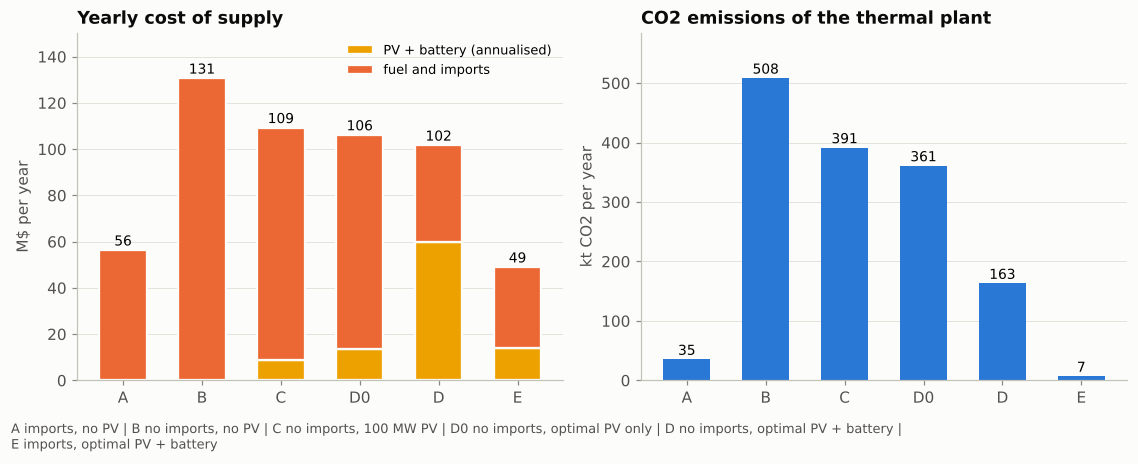

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.9))
labels = list(SCEN.keys())
ax = axes[0]
x = np.arange(len(res))
bottom = np.zeros(len(res))
parts = [("capex (M$/yr)", "PV + battery (annualised)", ENTITY["solar"]),
         ("fuel+imports (M$/yr)", "fuel and imports", ENTITY["thermal"])]
for col, lab, c in parts:
    ax.bar(x, res[col], bottom=bottom, color=c, width=0.6, label=lab, edgecolor="#fcfcfb", lw=1.5)
    bottom += res[col].values
for xi, v in zip(x, res["total cost (M$/yr)"]):
    ax.annotate(f"{v:.0f}", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("M$ per year")
ax.set_title("Yearly cost of supply"); ax.legend(loc="upper right", fontsize=8.5)
ax.set_ylim(0, bottom.max() * 1.15); ax.grid(axis="x", visible=False)
ax = axes[1]
ax.bar(x, res["CO2 (kt)"], color=SERIES[0], width=0.6)
for xi, v in zip(x, res["CO2 (kt)"]):
    ax.annotate(f"{v:.0f}", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("kt CO2 per year")
ax.set_title("CO2 emissions of the thermal plant"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, res["CO2 (kt)"].max() * 1.15)
fig.text(0.01, -0.06, "A imports, no PV | B no imports, no PV | C no imports, 100 MW PV | "
         "D0 no imports, optimal PV only | D no imports, optimal PV + battery |\n"
         "E imports, optimal PV + battery", fontsize=8.5, color=INK2)
fig.tight_layout()
save(fig, FIG / "cs07_cost_co2.png")
fig

## 7. How the optimal system runs: a hot-season week (scenario D, question 4)

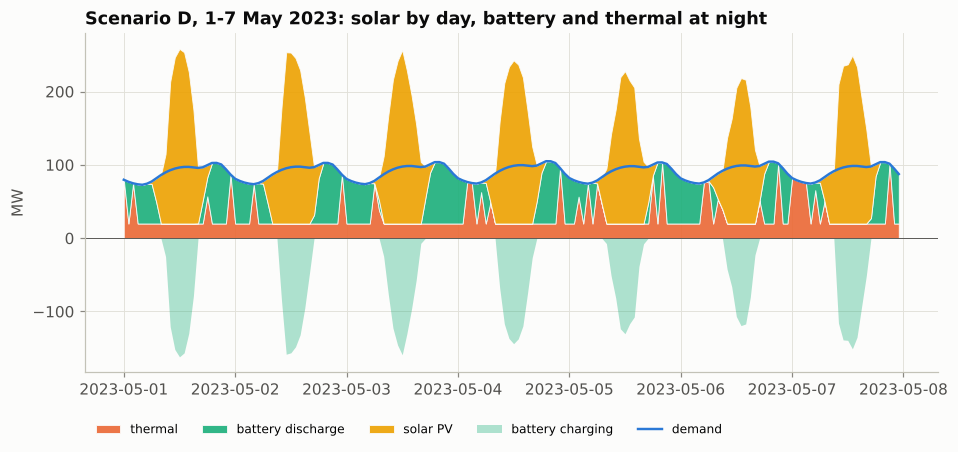

In [5]:
def dispatch_week(n, start, days=7, title="", path=None):
    idx = n.snapshots[(n.snapshots >= start) & (n.snapshots < pd.Timestamp(start) + pd.Timedelta(days=days))]
    gp = n.generators_t.p.loc[idx]
    sp = n.storage_units_t.p.loc[idx, "battery"]
    d = n.loads_t.p_set.loc[idx].sum(axis=1)
    fig, ax = plt.subplots(figsize=(10, 4.0))
    stack = [("import", "imports", gp["import"]), ("thermal", "thermal", gp["thermal"]),
             ("battery", "battery discharge", sp.clip(lower=0)), ("solar", "solar PV", gp["pv"])]
    stack = [s for s in stack if s[2].sum() > 1e-6]          # no empty series in the legend
    ax.stackplot(idx, *[v.values for *_, v in stack], colors=[ENTITY[k] for k, *_ in stack],
                 labels=[lab for _, lab, _ in stack], alpha=0.9, edgecolor="#fcfcfb", lw=0.6)
    ax.fill_between(idx, 0, sp.clip(upper=0).values, color=ENTITY["battery"], alpha=0.35, lw=0,
                    label="battery charging")
    ax.plot(idx, d.values, color=ENTITY["demand"], lw=1.6, label="demand")
    ax.axhline(0, color=INK2, lw=0.6)
    ax.set_ylabel("MW"); ax.set_title(title)
    ax.legend(loc="upper left", ncol=6, fontsize=8, bbox_to_anchor=(0, -0.12))
    if path:
        save(fig, path)
    return fig

dispatch_week(nets["D"], "2023-05-01", title="Scenario D, 1-7 May 2023: solar by day, battery and thermal at night",
              path=FIG / "cs07_week_D.png")

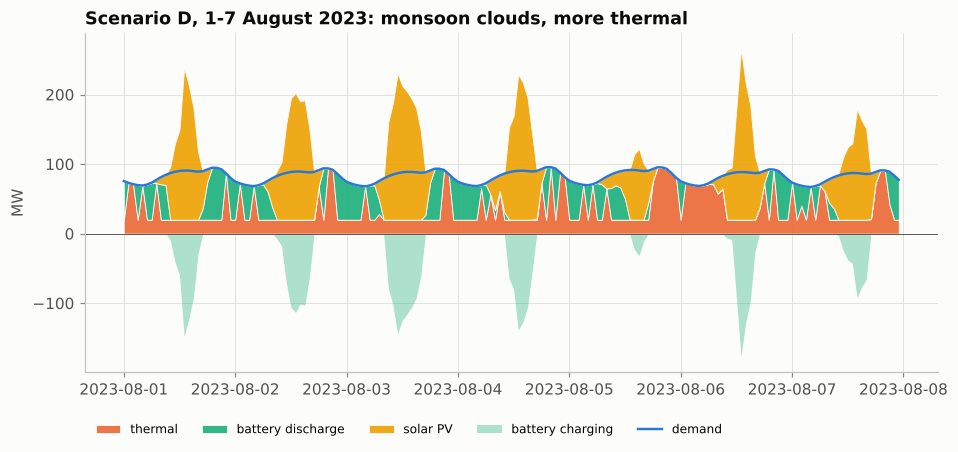

In [6]:
dispatch_week(nets["D"], "2023-08-01", title="Scenario D, 1-7 August 2023: monsoon clouds, more thermal",
              path=FIG / "cs07_week_D_august.png")

## 8. What limits the solar size? (question 3)
Two candidates: the **grid** (lines 1-3 and 3-4 must evacuate the PV output of bus 3) and
the **system's ability to absorb midday energy** (demand at midday minus the 20 MW thermal
must-run). The load-duration curves of the lines answer the first question.

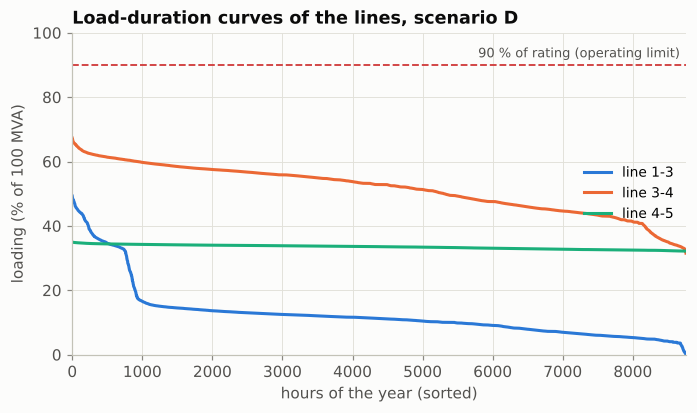

In [7]:
nD = nets["D"]
load_pct = 100 * nD.lines_t.p0.abs().div(nD.lines.s_nom)
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for ln, c in zip(["L1-3", "L3-4", "L4-5"], SERIES):
    dur = np.sort(load_pct[ln].values)[::-1]
    ax.plot(np.arange(len(dur)), dur, color=c, label=f"line {ln[1:]}")
limit_line(ax, 90, "90 % of rating (operating limit)", color=CRITICAL)
ax.set_xlabel("hours of the year (sorted)"); ax.set_ylabel("loading (% of 100 MVA)")
ax.set_title("Load-duration curves of the lines, scenario D")
ax.legend(loc="center right"); ax.set_xlim(0, 8760); ax.set_ylim(0, 100)
save(fig, FIG / "cs07_line_duration_D.png")
fig

In [8]:
print("Hours with a line at its operating limit, scenario D:", res.loc[NAMES["D"], "hours at line limit"])
print("Mean nodal prices, scenario D ($/MWh):", nD.buses_t.marginal_price.mean().round(1).to_dict())

Hours with a line at its operating limit, scenario D: 0.0
Mean nodal prices, scenario D ($/MWh): {'1': 129.8, '2': 129.8, '3': 129.8, '4': 129.8, '5': 129.8}


## 9. AC load-flow check at the critical hours (question 5)
The optimisation used a linear model of the grid. We now take the optimal hourly dispatch of
scenario D and run the **full AC load flow** at the two critical hours: the evening demand
peak and the hour of maximum solar injection.

In [9]:
def ac_check(n, hours):
    if getattr(n, "model", None) is not None:
        n.model.solver_model = None                 # a solved model cannot be copied otherwise
    m = n.copy()
    m.set_snapshots(hours)
    m.generators_t.p_set = n.generators_t.p.loc[hours].copy()
    m.storage_units_t.p_set = n.storage_units_t.p.loc[hours].copy()
    m.generators["p_nom"] = n.generators.p_nom_opt
    m.storage_units["p_nom"] = n.storage_units.p_nom_opt
    m.generators["control"] = "PQ"
    m.generators.loc["thermal", "control"] = "Slack"          # covers the AC losses
    run_pf(m)
    out = pd.DataFrame({"min |V| (p.u.)": m.buses_t.v_mag_pu.min(axis=1),
                        "bus": m.buses_t.v_mag_pu.idxmin(axis=1),
                        "max |V| (p.u.)": m.buses_t.v_mag_pu.max(axis=1),
                        "max loading (%)": 100 * np.maximum(np.hypot(m.lines_t.p0, m.lines_t.q0),
                                                            np.hypot(m.lines_t.p1, m.lines_t.q1)).div(m.lines.s_nom).max(axis=1),
                        "AC losses (MW)": (m.lines_t.p0 + m.lines_t.p1).sum(axis=1),
                        "solar (MW)": m.generators_t.p["pv"]})
    return out, m

peak_hour = demand.idxmax()
solar_hour = nD.generators_t.p["pv"].idxmax()
ac_tab, m_ac = ac_check(nD, pd.DatetimeIndex([peak_hour, solar_hour]))
ac_tab.index = ["evening demand peak " + str(peak_hour), "maximum solar " + str(solar_hour)]
ac_tab.to_csv(TAB / "cs07_ac_check.csv")
ac_tab.round(3)

,min |V| (p.u.),bus,max |V| (p.u.),max loading (%),AC losses (MW),solar (MW)
evening demand peak 2023-05-04 19:00:00,0.968,5,1.02,69.291,2.190,-0.000
maximum solar 2023-04-16 13:00:00,0.972,5,1.02,64.263,1.955,273.442


## 10. Interpretation and recommendations
* **Solar is the cheapest energy** here: about 51 $/MWh when fully used, against 180 $/MWh
  of fuel and 70 $/MWh of imports. The question is never "is PV cheaper?" but "how much PV
  can the system absorb?"
* **Without storage (D0)** the optimum stops at about 150 MW of PV with 20 % curtailment:
  at midday the demand, minus the 20 MW thermal must-run, cannot absorb more. **This, not
  the grid, limits solar**: the lines never exceed about 65 % of their rating.
* **With storage (D)** the limit moves: about 330 MW of PV and a 4-hour battery of about
  200 MW / 780 MWh supply 72 % of the yearly demand, fuel use falls by 68 % compared with
  B, and the yearly cost by 22 %. The battery sits at the solar bus, so it also smooths the
  flows on the lines (no congestion at any hour).
* **The 100 MW plan of the exercise (C)** is a good first step (-23 % fuel), but far from
  the optimum.
* **With imports available (E)**, cheap night imports leave little value to storage: about
  145 MW of PV and almost no battery, and the average cost drops from 78 to 68 $/MWh.
* **Security of supply:** with imports interrupted, the PV + battery system cuts the cost of
  the crisis from 180 to 140 $/MWh. The thermal plant is still needed at full size (peak
  104 MW in D) for the monsoon weeks and the evening peaks of cloudy days.
* **AC check:** at the evening peak and at the solar peak of scenario D, voltages stay
  within 0.95-1.05 p.u. and no line exceeds 70 % loading: the plan is technically feasible.

**Limits of this study:** fictitious grid and demand model; perfect foresight over the year;
no unit commitment details, no reserve margin for forecast errors, single weather year.
Next steps: multi-year weather (2015-2023), N-1 checks on the hourly dispatch, battery
degradation, and Renewables.ninja profiles for comparison.

In [10]:
pscs.save_summary("cs07", {
    "pv_source": pv_profile("niamey").name,
    "cf": cf.mean(), "yield_kwh_kwp": cf.sum(), "demand_gwh": demand.sum() / 1e3, "peak_mw": demand.max(),
    "pv_lcoe": A.pv_capital_cost() / cf.sum(),
    "scenarios": res.to_dict(orient="index"),
    "ac_check": ac_tab.to_dict(orient="index"),
    "lmp_D": nD.buses_t.marginal_price.mean().to_dict(),
})